## Example of opening a SWOT L2 SSH EXPERT Icechunk v2 store out-of-cloud

#### Python environment

icechunk == 2.1.2
xarray == 2026.7.0
earthaccess == 0.18.0
zarr == 3.2.1

In [ ]:
#!pip install "icechunk==2.1.2"

In [8]:
!pip list | grep -E "icec|^xarray|earth|^zarr"

earthaccess               0.19.0
icechunk                  2.1.2
xarray                    2026.7.0
zarr                      3.2.1


In [9]:
import icechunk
import xarray as xr
import earthaccess
import os
import numpy as np

#  mapping
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

In [10]:
# --- 1. Authenticate with your NASA Earthdata Login
auth = earthaccess.login()   # strategy defaults to netrc/env/interactive

# EDL bearer token
edl_token = auth.token["access_token"]

# --- 2. Configure HTTP Storage for the Icechunk Metadata ---
repo_url = (
    "https://archive.podaac.uat.earthdata.nasa.gov/podaac-uat-cumulus-public/virtual_collections/SWOT_L2_LR_SSH_Expert_D/SWOT_L2_LR_SSH_Expert_D.icechunk_v2.https"
)

storage = icechunk.http_storage(repo_url)

# --- 3. Override the Repository Config for the Virtual Chunks ---
config = icechunk.Repository.fetch_config(storage)

# Match the FULL prefix the chunks actually resolve to (see the error message)
https_prefix = "https://archive.swot.podaac.earthdata.nasa.gov/podaac-swot-ops-cumulus-protected/"

https_store = icechunk.http_store(
     headers={"Authorization": f"Bearer {edl_token}"}

)

config.set_virtual_chunk_container(
    icechunk.VirtualChunkContainer(https_prefix, https_store)
)

# --- 4. Authorize and Open Repo ---
auth_map = {
    https_prefix: icechunk.credentials.HttpAccess
}
#print(" auth map: ", auth_map)

repo = icechunk.Repository.open(
    storage,
    config=config,
    authorize_virtual_chunk_access=auth_map
)

# --- 5. Load the Dataset ---
session = repo.readonly_session("main")
ds = xr.open_zarr(session.store, consolidated=False)

print("Successfully loaded dataset using 100% pure HTTPS!")
print(ds)

Successfully loaded dataset using 100% pure HTTPS!
<xarray.Dataset> Size: 11TB
Dimensions:                                (granule: 27010, num_lines: 9866,
                                            num_pixels: 69, num_sides: 2)
Coordinates:
  * granule                                (granule) int64 216kB 0 1 ... 27009
    cycle                                  (granule) int64 216kB dask.array<chunksize=(27010,), meta=np.ndarray>
    filename                               (granule) <U72 8MB dask.array<chunksize=(1689,), meta=np.ndarray>
    ppass                                  (granule) int64 216kB dask.array<chunksize=(27010,), meta=np.ndarray>
    orbit                                  (granule) datetime64[ns] 216kB dask.array<chunksize=(27010,), meta=np.ndarray>
    latitude_nadir                         (num_lines) float64 79kB dask.array<chunksize=(9866,), meta=np.ndarray>
    longitude_nadir                        (num_lines) float64 79kB dask.array<chunksize=(9866,), meta=np.

In [11]:
# Do a CMR granule search and find the orbits in a specific space/time window. SWOT is 0-360 in longitude.
# This bbox for Indian/Southern Ocean
lat_min, lat_max = -80, 20
lon_min, lon_max = 0, 120

start_time = '2025-05-10T00:28:00'
end_time = '2025-05-10T23:28:00'

short_name = 'SWOT_L2_LR_SSH_EXPERT_D'

granule_result = earthaccess.search_data(
    short_name=short_name,
    temporal=(start_time, end_time),
    bounding_box=(lon_min, lat_min, lon_max, lat_max)
)
print(len(granule_result))


14


In [12]:
# Get granule start times from CMR granule search result. Will be used to subset into the VDS:
datetimes_str = [g['umm']['TemporalExtent']['RangeDateTime']['BeginningDateTime'][:-1] for g in granule_result]  # -1 to remove "Z" at end.
datetimes_obj = [np.datetime64(dts) for dts in datetimes_str]
#print(datetimes_obj)

In [14]:
# Mask (and subset)the entire VDS with the orbits found from the CMR space/time query and granule metadata parsing for start times
mask = ds.orbit.isin(datetimes_obj).compute()
data_vds_subset = ds.where(mask, drop=True)
data_vds_subset

<xarray.Dataset> Size: 6GB
Dimensions:                                (granule: 14, num_lines: 9866,
                                            num_pixels: 69, num_sides: 2)
Coordinates:
  * granule                                (granule) int64 112B 16570 ... 16588
    cycle                                  (granule) int64 112B 32 32 ... 32 32
    filename                               (granule) <U72 4kB 'SWOT_L2_LR_SSH...
    ppass                                  (granule) int64 112B 340 342 ... 361
    orbit                                  (granule) datetime64[ns] 112B 2025...
    latitude_nadir                         (num_lines) float64 79kB dask.array<chunksize=(9866,), meta=np.ndarray>
    longitude_nadir                        (num_lines) float64 79kB dask.array<chunksize=(9866,), meta=np.ndarray>
    latitude                               (granule, num_lines, num_pixels) float64 76MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    longitude                              (granule, num_lines, num_pixels) float64 76MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
Dimensions without coordinates: num_lines, num_pixels, num_sides
Data variables: (12/98)
    ancillary_surface_classification_flag  (granule, num_lines, num_pixels) float32 38MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    depth_or_elevation                     (granule, num_lines, num_pixels) float64 76MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    cross_track_distance                   (granule, num_lines, num_pixels) float32 38MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    distance_to_coast                      (granule, num_lines, num_pixels) float64 76MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    cross_track_angle                      (granule, num_lines) float64 1MB dask.array<chunksize=(1, 9866), meta=np.ndarray>
    dynamic_ice_flag                       (granule, num_lines, num_pixels) float32 38MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    ...                                     ...
    wind_speed_ssb_cor_source_2            (granule, num_lines, num_pixels) float32 38MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    x_factor                               (granule, num_lines, num_pixels) float32 38MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    volumetric_correlation_uncert          (granule, num_lines, num_pixels) float64 76MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    wind_speed_rad                         (granule, num_lines, num_sides) float64 2MB dask.array<chunksize=(1, 9866, 2), meta=np.ndarray>
    velocity_heading                       (granule, num_lines) float64 1MB dask.array<chunksize=(1, 9866), meta=np.ndarray>
    wind_speed_ssb_cor_source              (granule, num_lines, num_pixels) float32 38MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
Attributes: (12/22)
    Conventions:                      CF-1.7
    title:                            Level 2 Low Rate Sea Surface Height Dat...
    institution:                      CNES
    source:                           Ka-band radar interferometer
    platform:                         SWOT
    reference_document:               D-56407_SWOT_Product_Description_L2_LR_SSH
    ...                               ...
    xref_param_l2_lr_precalssh_file:  SWOT_Param_L2_LR_PreCalSSH_20000101T000...
    xref_reforbittrack_files:         SWOT_RefOrbitTrack125mPass1_Nom_2000010...
    xref_geco_database_version:       v107
    ellipsoid_semi_major_axis:        6378137.0
    ellipsoid_flattening:             0.0033528106647474805
    references:                       V1.4.1

In [15]:
%%time
# Perform SSH variable maskings for the large numeric  "fill_values" and other assignments
ssh = data_vds_subset.ssh_karin.load()
ssh = ssh.where(ssh < 1000)

lat = data_vds_subset.latitude
lon = data_vds_subset.longitude

CPU times: user 1.45 s, sys: 352 ms, total: 1.8 s
Wall time: 10.7 s


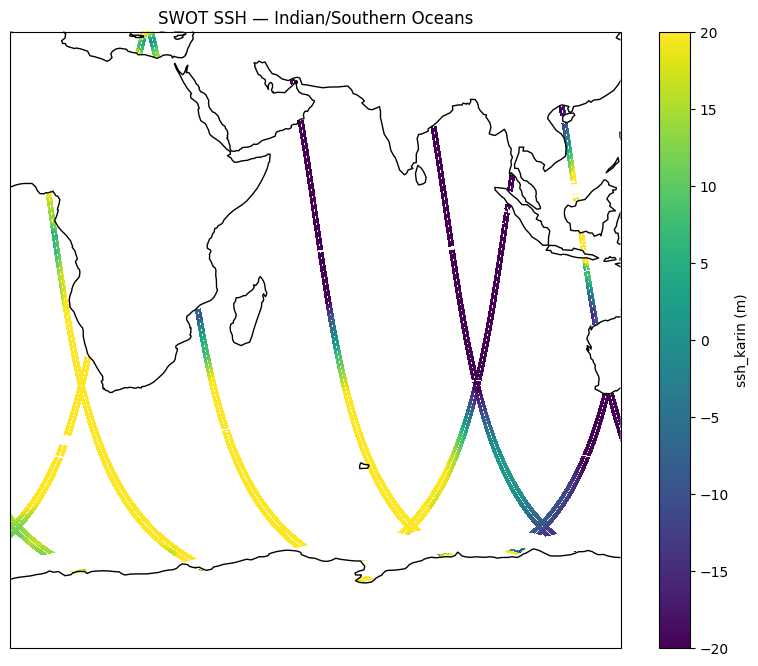

CPU times: user 8.48 s, sys: 550 ms, total: 9.03 s
Wall time: 1min 55s


In [8]:
%%time

fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent([lon_min, lon_max, lat_min, lat_max])
ax.coastlines()

for k in range(ssh.sizes["granule"]):
    ssh_i = ssh.isel(granule=k)
    lat_i = lat.isel(granule=k)
    lon_i = lon.isel(granule=k)
    
    pcm = ax.pcolormesh(
        lon_i,
        lat_i,
        ssh_i,
        shading="auto",
        cmap="viridis",
        vmin=-20,
        vmax=20,
        transform=ccrs.PlateCarree()
    )

plt.colorbar(pcm, ax=ax, label="ssh_karin (m)")
plt.title("SWOT SSH — Indian/Southern Oceans")
plt.show()